# Example of the aitlas toolbox in the context of sematic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox.

## Import the required packages

In [ ]:
from aitlas.datasets import MidAirDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import matplotlib.pyplot as plt

## Visualize images and masks

In [25]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/MidAir/",
}
dataset = MidAirDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 423676


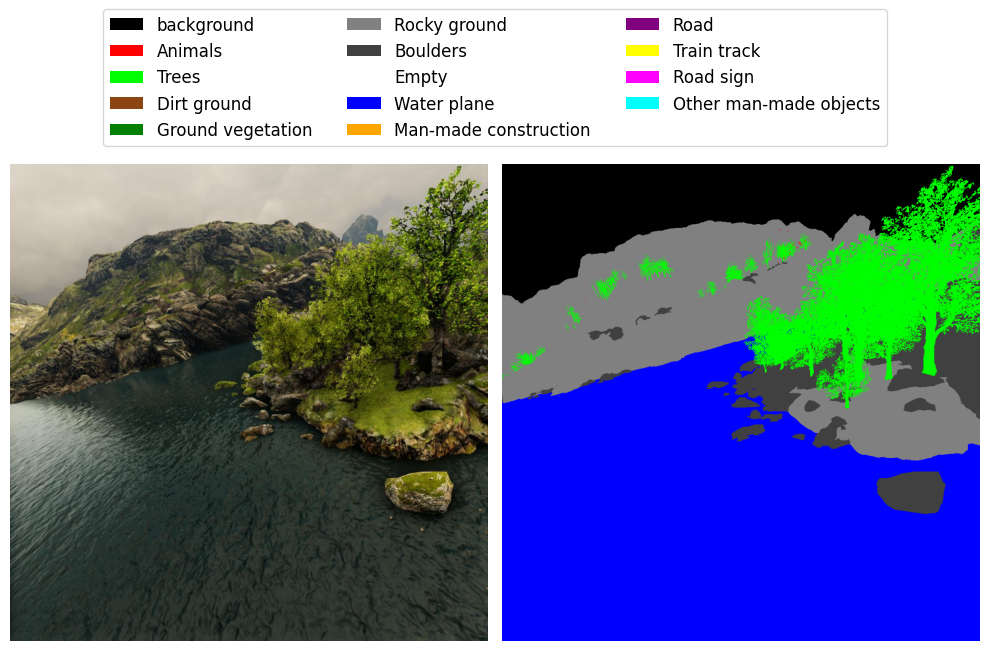

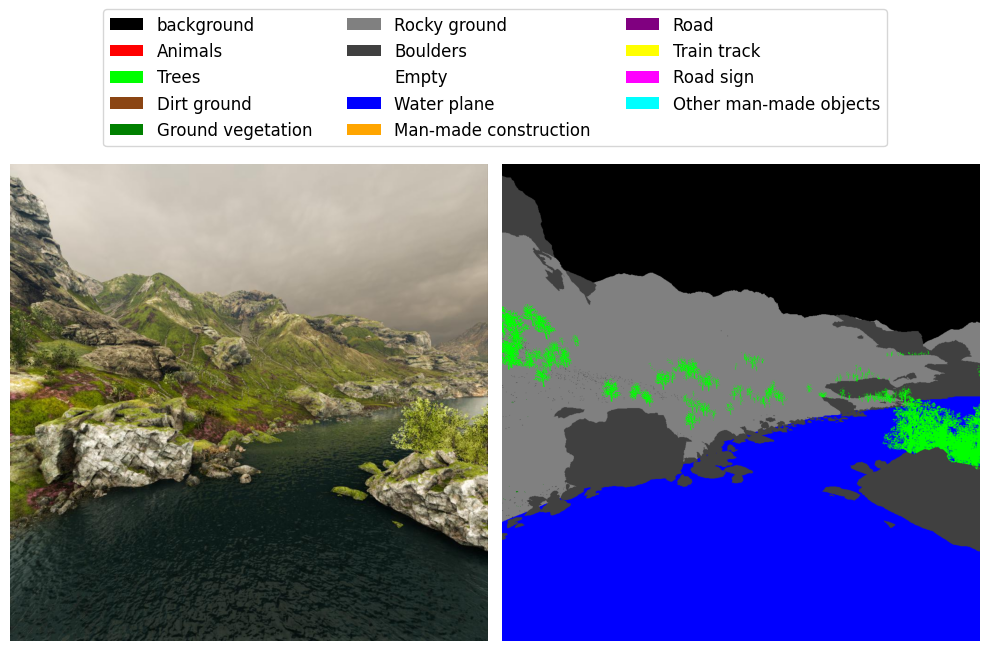

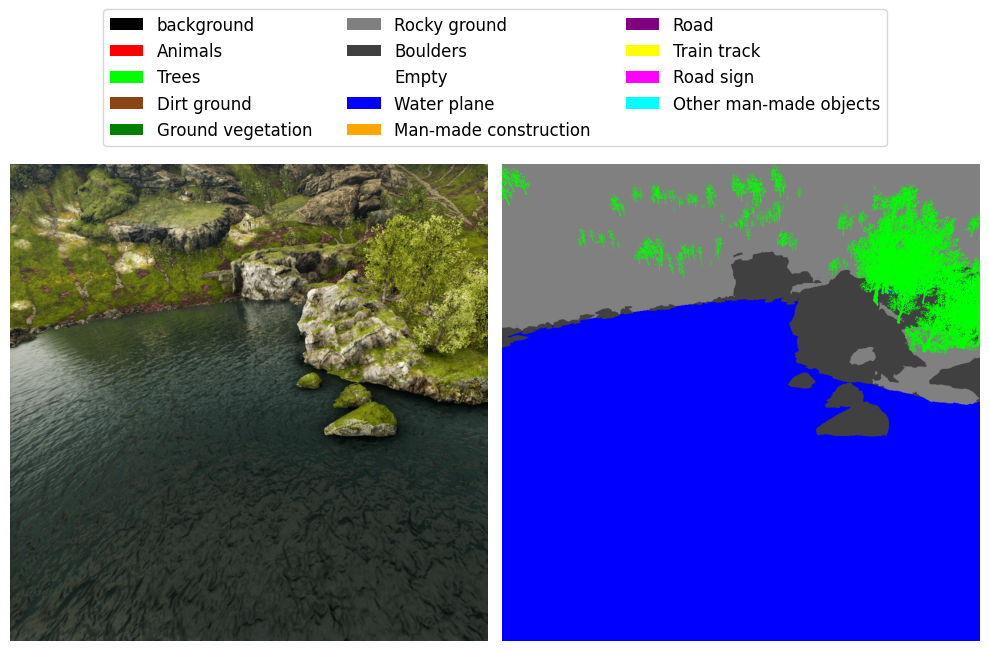

In [26]:
dataset.show_image(10)
dataset.show_image(100)
dataset.show_image(300);

In [10]:
dataset.data_distribution_table()

,Number of pixels
background,6.293714e+10
Animals,8.036901e+07
Trees,3.508626e+10
Dirt ground,0.000000e+00
Ground vegetation,8.597041e+10
Rocky ground,6.196220e+10
Boulders,2.076904e+10
empty,0.000000e+00
Water plane,1.097810e+10
Man-made construction,0.000000e+00


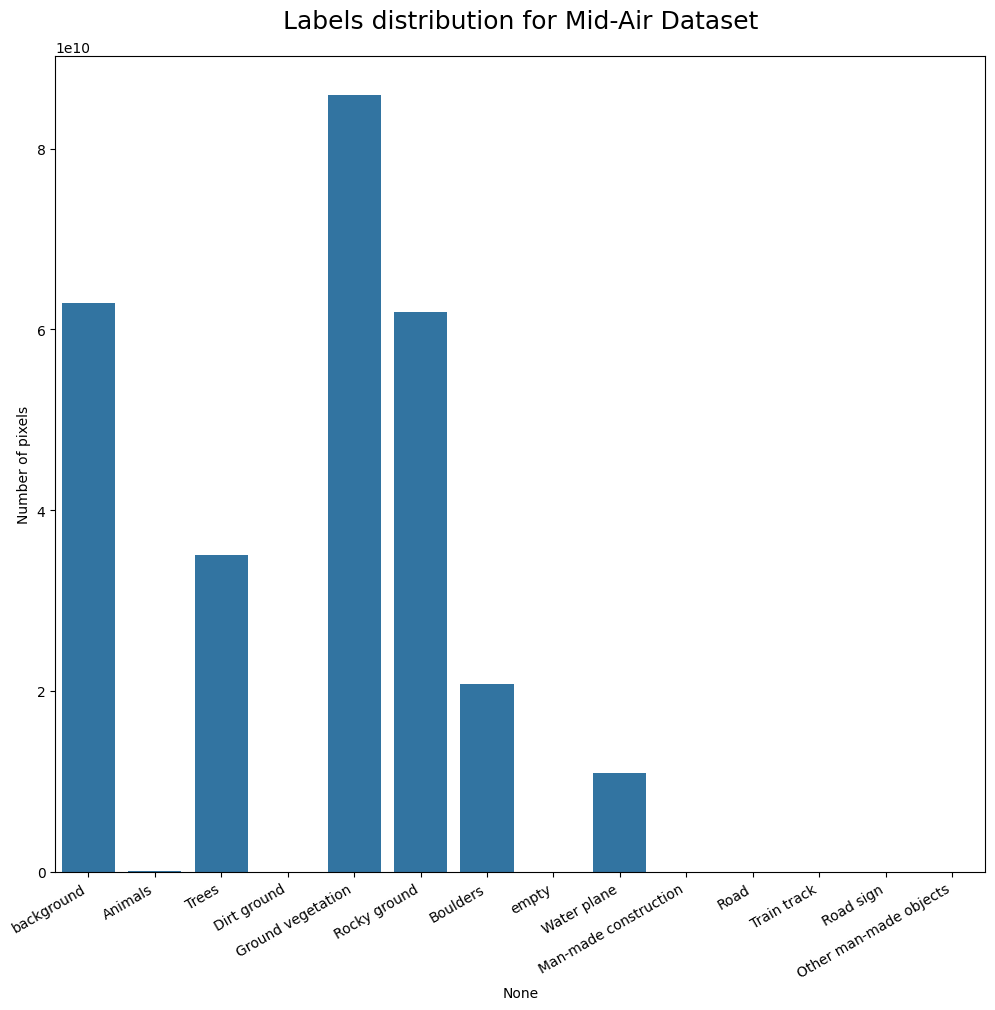

In [11]:
dataset.data_distribution_barchart();

## Load training data ##

In [27]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/MidAir/",
    "csv_file": "/home/dragik/data/FAIR_EO/MidAir/mid_air_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = MidAirDataset(train_dataset_config)

len(train_dataset)

254212

## Create the model ##

In [28]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/MidAir"
model_config = {
    "num_classes": 14, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-23 07:06:21,802 INFO Starting training.
training: 100%|██████████| 6623/6623 [1:58:45<00:00,  1.08s/it]
2025-09-23 09:05:06,997 INFO epoch: 1, time: 7125, loss:  0.12633
testing on train set: 100%|██████████| 6623/6623 [2:00:35<00:00,  1.09s/it]  
2025-09-23 11:05:44,368 INFO IOU:0.715226880613987, IOU mean:0.3156281242976191, IOU per Class:[0.93385081 0.         0.37283573 0.         0.72475918 0.61083679
 0.82649396 0.         0.95001728 0.         0.         0.
 0.         0.        ]
training: 100%|██████████| 6623/6623 [2:00:02<00:00,  1.09s/it]
2025-09-23 13:05:47,367 INFO epoch: 2, time: 7203, loss:  0.07543
testing on train set: 100%|██████████| 6623/6623 [1:59:26<00:00,  1.08s/it]  
2025-09-23 15:05:14,359 INFO IOU:0.716647497329046, IOU mean:0.3166156906853426, IOU per Class:[0.93424474 0.         0.37953133 0.         0.72792446 0.60349892
 0.83949369 0.         0.94792652 0.         0.         0.
 0.         0.        ]
training: 100%|██████████| 6623/6623 [2:02:03<

0.06563146540239055

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/MidAir/",
    "csv_file": "/home/dragik/data/FAIR_EO/MidAir/mid_air_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = MidAirDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/MidAir/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

26490


2025-09-25 06:35:09,553 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/MidAir/checkpoint.pth.tar
2025-09-25 06:35:10,036 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/MidAir/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 6623/6623 [11:43<00:00,  9.41it/s]


[{'IOU': 0.7236526885802422,
  'IOU mean': 0.31895704202033237,
  'IOU per Class': array([0.93849728, 0.        , 0.37410577, 0.        , 0.73266627,
         0.62368627, 0.84034714, 0.        , 0.95609587, 0.        ,
         0.        , 0.        , 0.        , 0.        ])}]

## Predictions

2025-11-24 13:05:12,053 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/MidAir/checkpoint.pth.tar
2025-11-24 13:05:12,790 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/MidAir/checkpoint.pth.tar at epoch 11


84738


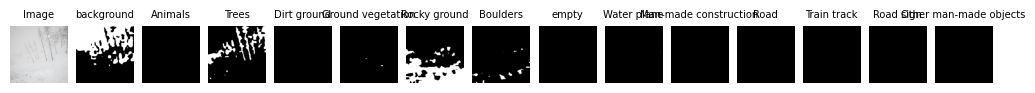

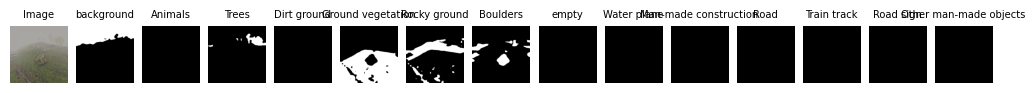

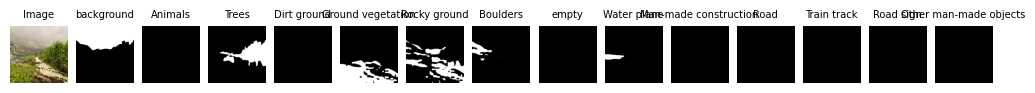

In [30]:
model_path = "/home/dragik/data/FAIR_EO/experiments/MidAir/checkpoint.pth.tar"
labels = ["background",
        "Animals",
        "Trees",
        "Dirt ground",
        "Ground vegetation",
        "Rocky ground",
        "Boulders",
        "empty",
        "Water plane",
        "Man-made construction",
        "Road", 
        "Train track",
        "Road sign",
        "Other man-made objects"]
transform = ResizeToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/MidAir/",
    "csv_file": "/home/dragik/data/FAIR_EO/MidAir/mid_air_test.csv"
}

test_dataset = MidAirDataset(test_dataset_config)
print(len(test_dataset))

plt.rcParams.update({'font.size': 6})

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_masks(image, labels, transform)